In [2]:
import os
os.chdir("/home/jovyan/work/repo_conteo_gallinas")
os.environ["CUDA_VISIBLE_DEVICES"] = "0, 2"

import torch
from ultralytics import YOLO

import time
import pandas as pd

from siuba import *

import shutil
from itertools import product


In [6]:
def evaluar_modelo(MODEL_EPOCHS, MODEL_BATCH, MODEL_LR, MODEL_OPTIMIZER, pos):

    # Eliminar carpetas de resultados
    if os.path.exists("runs"):
        shutil.rmtree("runs")

    # Modelo
    model = YOLO("model/yolo26m.pt")
    
    # Empezar el entrenamiento
    model.train(
        data="/home/jovyan/work/repo_conteo_gallinas/artifacts/full_dataset.yaml",
        epochs=MODEL_EPOCHS,
        batch=MODEL_BATCH,
        lr0=MODEL_LR,
        optimizer=MODEL_OPTIMIZER,
        seed=123,
        deterministic=True,
        # device=0,
        device=[0, 1],
        workers=0,
        project='.',
        name='.'
    )

    # Lectura resultados
    df = pd.read_csv("runs/detect/results.csv")
    epoca_final = int(df["epoch"].max())
    tiempo_segundos = float(df["time"].max())
    tiempo_min = tiempo_segundos/60
    tiempo_hora = tiempo_min/60
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    map50_final = float(best["metrics/mAP50(B)"])
    map5095_final = float(best["metrics/mAP50-95(B)"])
    precision_final = float(best["metrics/precision(B)"])
    recall_final = float(best["metrics/recall(B)"])

    # Número de imágenes
    imagenes = len(os.listdir("data/deteccion/imgs"))
    imagenes_train = len(os.listdir("data/dataset/train/images"))
    imagenes_val = len(os.listdir("data/dataset/val/images"))

    # Información sonsolidada
    data_list = {
        'numero': pos
        , 'modelo_yolo': "yolo26m"
        , 'epocas_inicial': MODEL_EPOCHS
        , 'epocas_fin': epoca_final
        , 'batch': MODEL_BATCH
        , 'learning_rate': MODEL_LR
        , 'optimizer': MODEL_OPTIMIZER
        , 'total_imagenes': imagenes
        , 'total_imagenes_train': imagenes_train
        , 'total_imagenes_val': imagenes_val

        , 'tiempo_minutos': tiempo_min
        , 'tiempo_horas': tiempo_hora
        , 'map50': map50_final
        , 'map50_95': map5095_final
        , "precision": precision_final
        , "recall": recall_final
    }

    return data_list
    



In [ ]:

ls_epocas = [50, 100, 150]
ls_batch = [6, 8, 10, 12]
ls_optimizador = ["SGD", "auto"]
ls_lr = [0.1, 0.01, 0.001]


combinaciones = list(product(ls_epocas, ls_batch, ls_lr, ls_optimizador))
list_epocas, list_batch, list_lr, list_optimizador = zip(*combinaciones)

list_dict_datos = list()
pos = 1
for i, j, k, m in zip(list_epocas, list_batch, list_lr, list_optimizador):

    data_resultado = evaluar_modelo(i, j, k, m, pos)
    list_dict_datos.append(data_resultado)
    pos += 1
    print(f"total: {pos-1}/{len(list_epocas)}\n")
    

DataResultado11 = pd.DataFrame(list_dict_datos)



Ultralytics 8.4.96 🚀 Python-3.13.11 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX 6000 Ada Generation, 48640MiB)
                                                       CUDA:1 (NVIDIA RTX 6000 Ada Generation, 48632MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jovyan/work/repo_conteo_gallinas/artifacts/full_dataset.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.1, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



     67/100      6.55G      2.182      1.329   0.006363        257        640: 100% ━━━━━━━━━━━━ 13/13 6.4it/s 2.0s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 6.7it/s 0.3s0.5s
                   all         38       3851      0.632      0.634      0.616      0.235

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     68/100      6.55G      2.164      1.294   0.005824        403        640: 100% ━━━━━━━━━━━━ 13/13 6.4it/s 2.0s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 6.6it/s 0.3s0.5s
                   all         38       3851       0.63      0.636      0.621      0.237

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     69/100      6.55G      2.177      1.305   0.006465        285        640: 100% ━━━━━━━━━━━━ 13/13 6.5it/s 2.0s0.1s
                 Class     Images  Instances  

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



      1/150      3.17G      2.716      3.054   0.008542        445        640: 100% ━━━━━━━━━━━━ 19/19 1.1it/s 16.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.7s0.3s
                   all         38       3851      0.118      0.212     0.0411    0.00892

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/150      3.54G      2.339      2.131   0.006567        710        640: 100% ━━━━━━━━━━━━ 19/19 7.0it/s 2.7s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 9.8it/s 0.3s0.3s
                   all         38       3851      0.274       0.36      0.188     0.0491

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/150      3.54G      2.243       1.91    0.00632        391        640: 100% ━━━━━━━━━━━━ 19/19 7.9it/s 2.4s0.1s
                 Class     Images  Instances 

In [10]:
DataResultado11


,numero,modelo_yolo,epocas_inicial,epocas_fin,batch,learning_rate,optimizer,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall
0,1,yolo26m,50,50,6,0.100,SGD,189,149,38,3.447083,0.057451,0.37797,0.12286,0.44344,0.44118
1,2,yolo26m,50,50,6,0.100,auto,189,149,38,3.212050,0.053534,0.64266,0.24201,0.64689,0.64684
2,3,yolo26m,50,50,6,0.010,SGD,189,149,38,2.976383,0.049606,0.62700,0.24007,0.62915,0.64788
3,4,yolo26m,50,50,6,0.010,auto,189,149,38,3.204083,0.053401,0.64266,0.24201,0.64689,0.64684
4,5,yolo26m,50,50,6,0.001,SGD,189,149,38,2.990600,0.049843,0.56110,0.20183,0.58382,0.59725
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,68,yolo26m,150,141,12,0.100,auto,189,149,38,7.046367,0.117439,0.64307,0.23894,0.64025,0.63724
68,69,yolo26m,150,150,12,0.010,SGD,189,149,38,6.994517,0.116575,0.66537,0.25300,0.67068,0.65386
69,70,yolo26m,150,141,12,0.010,auto,189,149,38,7.061367,0.117689,0.64307,0.23894,0.64025,0.63724
70,71,yolo26m,150,150,12,0.001,SGD,189,149,38,7.031733,0.117196,0.64906,0.24811,0.65261,0.64733


In [ ]:
DataResultado11.to_csv("artifacts/yolo26_ft_gs_11.csv", encoding = "utf-8", index = False)


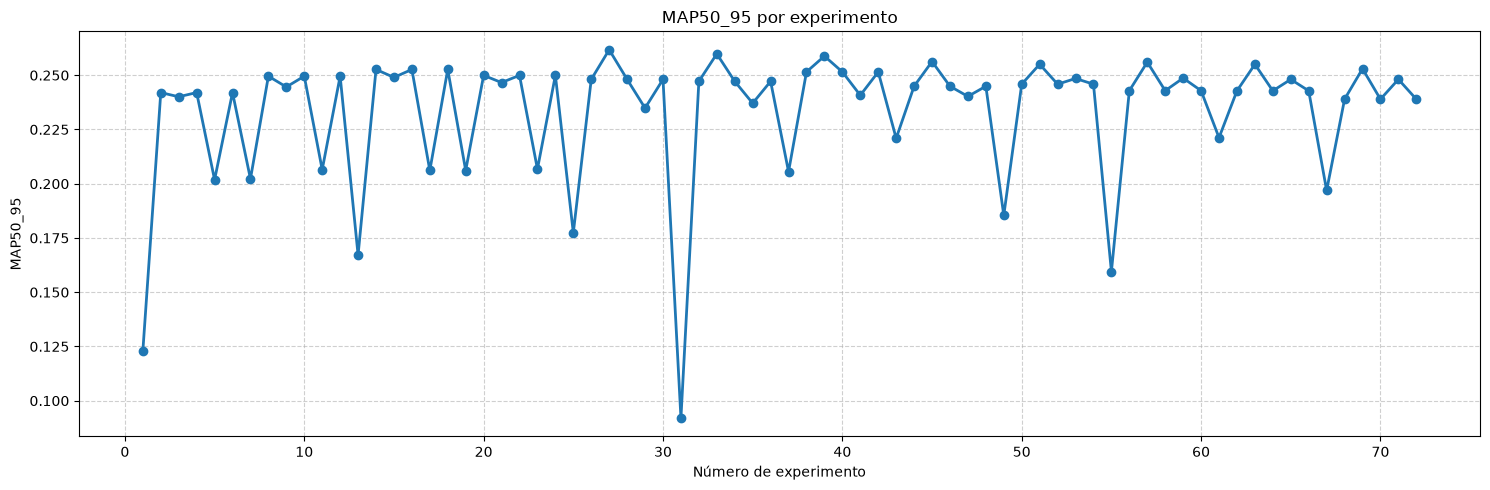

In [14]:
# Grafico
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    DataResultado11["numero"],
    DataResultado11["map50_95"],
    marker="o",
    linewidth=2,
    color="tab:blue"
)

plt.title("MAP50_95 por experimento")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


## Agregarle numero

In [2]:
ls_epocas = [50, 100, 150]
ls_batch = [6, 8, 10, 12]
ls_optimizador = ["SGD", "AdamW"]
ls_lr = [0.1, 0.01, 0.001]


combinaciones = list(product(ls_epocas, ls_batch, ls_lr, ls_optimizador))
list_epocas, list_batch, list_lr, list_optimizador = zip(*combinaciones)


In [4]:
len(list_epocas)

72

In [7]:
list_dict_datos = list()
cont = 1
for i, j, k, m in zip(list_epocas, list_batch, list_lr, list_optimizador):
    dict_data = {
        'numero': cont
        , 'epocas_inicial': i
        , 'batch': j
        , 'learning_rate': k
        , 'optimizer': m
    }
    list_dict_datos.append(dict_data)
    cont += 1
    

In [11]:
DataPos11 = pd.DataFrame(list_dict_datos)
DataPos11


,numero,epocas_inicial,batch,learning_rate,optimizer
0,1,50,6,0.100,SGD
1,2,50,6,0.100,AdamW
2,3,50,6,0.010,SGD
3,4,50,6,0.010,AdamW
4,5,50,6,0.001,SGD
...,...,...,...,...,...
67,68,150,12,0.100,AdamW
68,69,150,12,0.010,SGD
69,70,150,12,0.010,AdamW
70,71,150,12,0.001,SGD


In [13]:
# Leer data resultado
DataResultado11 = pd.read_csv("artifacts/data_comparativa_modelos_11.csv")
DataResultado11


,epocas_inicial,epocas_fin,batch,learning_rate,optimizer,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall
0,150,150,8,0.010,SGD,63,50,13,3.182633,0.053044,0.62927,0.22499,0.66027,0.65241
1,150,150,6,0.010,SGD,63,50,13,3.722767,0.062046,0.63592,0.22440,0.68010,0.63168
2,150,150,10,0.010,SGD,63,50,13,2.784250,0.046404,0.63515,0.22378,0.67402,0.65709
3,150,150,12,0.010,SGD,63,50,13,2.827133,0.047119,0.63468,0.22166,0.67730,0.62968
4,100,100,6,0.001,AdamW,63,50,13,2.865367,0.047756,0.61625,0.21575,0.64591,0.60481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,150,150,12,0.100,AdamW,63,50,13,5.929683,0.098828,0.02256,0.00422,0.07179,0.18717
68,50,50,6,0.100,AdamW,63,50,13,2.458800,0.040980,0.01589,0.00271,0.06201,0.13904
69,150,150,6,0.100,AdamW,63,50,13,6.772117,0.112869,0.01648,0.00264,0.06900,0.15709
70,100,100,6,0.100,AdamW,63,50,13,4.791633,0.079861,0.01637,0.00263,0.07873,0.10963


In [15]:
DataResultado12 = (
    DataPos11
    >> left_join(
        _
        , DataResultado11
        , on = {"epocas_inicial": "epocas_inicial"
               , "batch": "batch"
               , "learning_rate": "learning_rate"
               , "optimizer": "optimizer"
               }
    )
)



,numero,epocas_inicial,batch,learning_rate,optimizer,epocas_fin,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall
0,1,50,6,0.100,SGD,50,63,50,13,1.408758,0.023479,0.38426,0.12291,0.35397,0.58957
1,2,50,6,0.100,AdamW,50,63,50,13,2.458800,0.040980,0.01589,0.00271,0.06201,0.13904
2,3,50,6,0.010,SGD,50,63,50,13,1.423165,0.023719,0.54482,0.18040,0.61843,0.58938
3,4,50,6,0.010,AdamW,50,63,50,13,1.953000,0.032550,0.30926,0.08483,0.39609,0.39840
4,5,50,6,0.001,SGD,50,63,50,13,1.435610,0.023927,0.31740,0.08761,0.38757,0.44248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,68,150,12,0.100,AdamW,150,63,50,13,5.929683,0.098828,0.02256,0.00422,0.07179,0.18717
68,69,150,12,0.010,SGD,150,63,50,13,2.827133,0.047119,0.63468,0.22166,0.67730,0.62968
69,70,150,12,0.010,AdamW,102,63,50,13,3.966767,0.066113,0.01881,0.00440,0.07718,0.20120
70,71,150,12,0.001,SGD,150,63,50,13,2.861267,0.047688,0.58651,0.20417,0.63850,0.59225


In [16]:
(
    DataResultado12
    >> arrange(-_.map50_95)
)


,numero,epocas_inicial,batch,learning_rate,optimizer,epocas_fin,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall
56,57,150,8,0.010,SGD,150,63,50,13,3.182633,0.053044,0.62927,0.22499,0.66027,0.65241
50,51,150,6,0.010,SGD,150,63,50,13,3.722767,0.062046,0.63592,0.22440,0.68010,0.63168
62,63,150,10,0.010,SGD,150,63,50,13,2.784250,0.046404,0.63515,0.22378,0.67402,0.65709
68,69,150,12,0.010,SGD,150,63,50,13,2.827133,0.047119,0.63468,0.22166,0.67730,0.62968
29,30,100,6,0.001,AdamW,100,63,50,13,2.865367,0.047756,0.61625,0.21575,0.64591,0.60481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,68,150,12,0.100,AdamW,150,63,50,13,5.929683,0.098828,0.02256,0.00422,0.07179,0.18717
1,2,50,6,0.100,AdamW,50,63,50,13,2.458800,0.040980,0.01589,0.00271,0.06201,0.13904
49,50,150,6,0.100,AdamW,150,63,50,13,6.772117,0.112869,0.01648,0.00264,0.06900,0.15709
25,26,100,6,0.100,AdamW,100,63,50,13,4.791633,0.079861,0.01637,0.00263,0.07873,0.10963


In [20]:
DataResultado12.to_csv("artifacts/data_comparativa_modelos_11_1.csv", encoding = "utf-8", index = False)


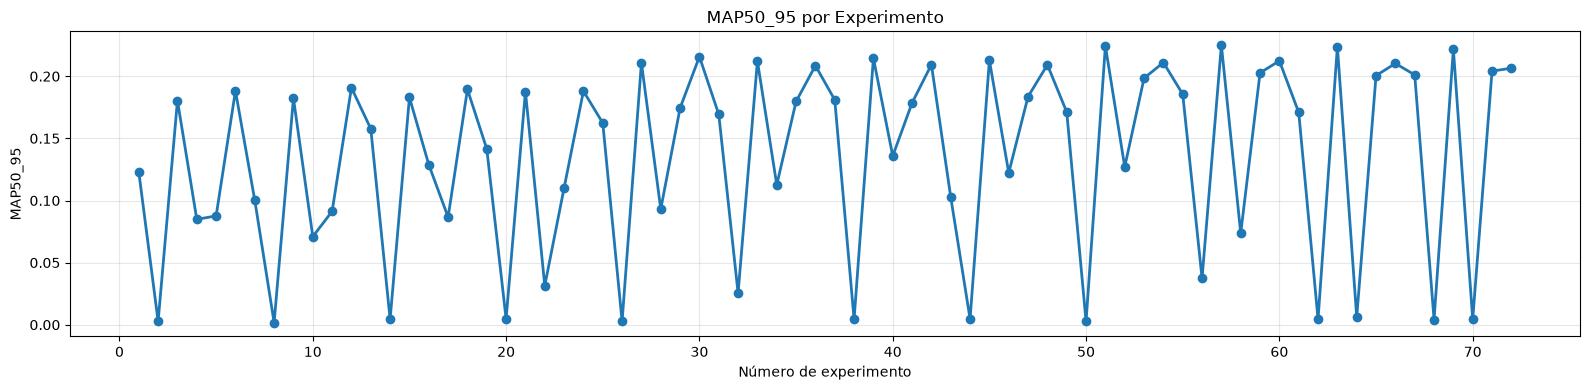

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 4))
plt.plot(
    DataResultado12["numero"],
    DataResultado12["map50_95"],
    marker="o",
    linewidth=2
)

plt.title("MAP50_95 por Experimento")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()